# Chapter 16 · Numerical methods: interactive demos

Companion to Chapter 16 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/16-numerics.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the model is Black–Scholes under the risk-neutral measure, where every price has a closed form:
that is what lets us measure the errors of the numerical methods exactly.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import time
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider

from ieor222.blackscholes import call, put, greeks, crr_parameters
from ieor222.binomial import early_exercise_boundary
from ieor222.numerics import (american_put_fd, bs_log_coefficients, call_payoff_sd, convergence_table,
                              european_fd, explicit_s_grid, grid_greeks, log_grid, mc_european, mc_summary,
                              pinn_eval, pinn_train, power_claim_rmse, theta_scheme)
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()

## 1. Monte Carlo: confidence intervals and their coverage

The Monte Carlo price of a call is the average of $M$ simulated discounted payoffs, and the interval
$\hat p_M\pm1.96\,s_M/\sqrt M$ contains the true price with probability close to $95\%$ when $M$ is large
(Theorem 16.1). On the left, estimates for growing $M$; on the right, the interval computed again and again
from independent samples of size $M$, with the fraction of intervals that contain the exact price.

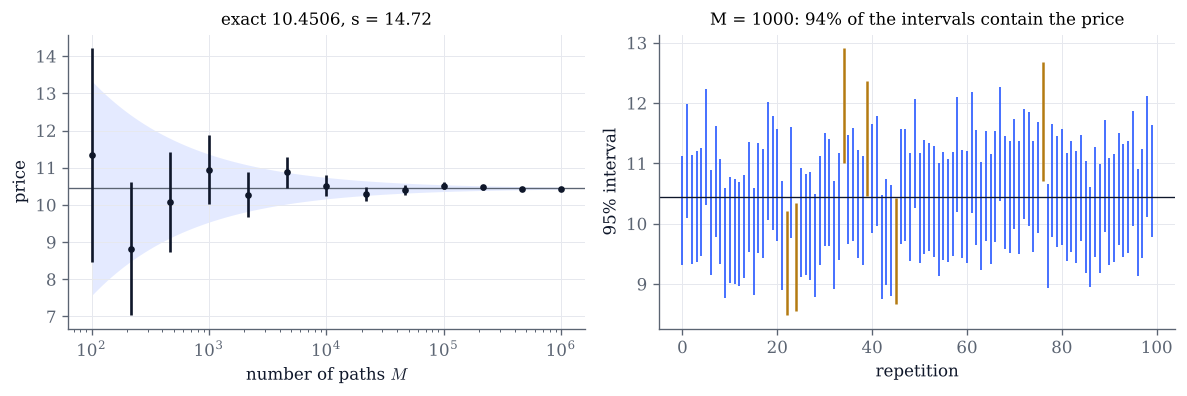

In [2]:
def monte_carlo(K=100.0, sigma=0.2, T=1.0, M=1000, repetitions=100, seed=0):
    S0, r = 100.0, 0.05
    payoff = lambda s: np.maximum(s - K, 0.0)
    exact = call(S0, K, T, r, sigma)
    sd = call_payoff_sd(S0, K, T, r, sigma)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    Ms = np.unique(np.round(np.logspace(2, 6, 13)).astype(int))
    est = [mc_european(payoff, S0, T, r, sigma, m, seed=seed + i) for i, m in enumerate(Ms)]
    grid = np.logspace(2, 6, 100)
    ax.fill_between(grid, exact - 1.96 * sd / np.sqrt(grid), exact + 1.96 * sd / np.sqrt(grid), color=COBALT, alpha=0.12, lw=0)
    ax.axhline(exact, color=GREY, lw=0.8)
    ax.errorbar(Ms, [e["mean"] for e in est], yerr=[e["half_width"] for e in est], fmt="o", ms=3, color=INK)
    ax.set_xscale("log")
    ax.set(xlabel="number of paths $M$", ylabel="price", title=f"exact {exact:.4f}, s = {sd:.2f}")
    rng = np.random.default_rng(seed + 999)
    Z = rng.standard_normal((repetitions, M))
    S = S0 * np.exp(sigma * np.sqrt(T) * Z + (r - 0.5 * sigma**2) * T)
    summaries = [mc_summary(np.exp(-r * T) * payoff(s)) for s in S]
    lo = np.array([u["low"] for u in summaries]); hi = np.array([u["high"] for u in summaries])
    hit = (lo <= exact) & (exact <= hi)
    idx = np.arange(repetitions)
    ax2.vlines(idx[hit], lo[hit], hi[hit], color=COBALT, lw=1)
    ax2.vlines(idx[~hit], lo[~hit], hi[~hit], color=GOLD, lw=1.5)
    ax2.axhline(exact, color=INK, lw=0.8)
    ax2.set(xlabel="repetition", ylabel="95% interval", title=f"M = {M}: {hit.mean():.0%} of the intervals contain the price")
    fig.tight_layout()
    plt.show()

monte_carlo()

In [3]:
# Explore: with a high strike most payoffs vanish. What happens to the coverage when M is small?
interact(monte_carlo,
         K=FloatSlider(value=100.0, min=60.0, max=200.0, step=5.0, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         T=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="T"),
         M=IntSlider(value=1000, min=20, max=20000, step=20, continuous_update=False, description="M"),
         repetitions=IntSlider(value=100, min=20, max=300, step=20, continuous_update=False, description="repetitions"),
         seed=IntSlider(value=0, min=0, max=50, continuous_update=False, description="seed"));

### Monte Carlo with a discretized model

When $S_T$ cannot be sampled exactly, an Euler scheme with $n$ steps adds a bias of order $1/n$, and the cost of a
path is $n$ normal draws (Proposition 16.3). For the claim $S_T^2$ with the Euler scheme on $S$, the bias and the variance
are explicit (Example 16.4), so the root mean square error $\sqrt{\beta^2+\mathrm{Var}/M}$ can be drawn exactly as a
function of the cost $nM$. With $n$ fixed the error stalls at the bias; balancing $n$ and $M$ gives the slope $-1/3$.

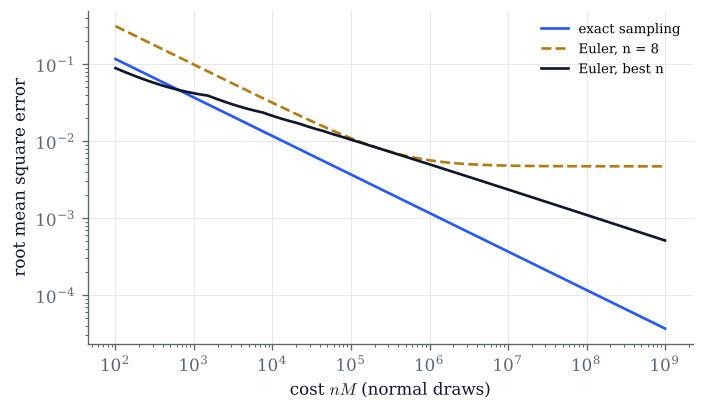

at a budget of 1e8 draws the best number of steps is n = 60


In [4]:
def cost_accuracy(sigma=0.4, r=0.05, T=1.0, n=8):
    C = np.logspace(2, 9, 120)
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.loglog(C, power_claim_rmse(1.0, T, r, sigma, 0, C), color=COBALT, label="exact sampling")
    ax.loglog(C, power_claim_rmse(1.0, T, r, sigma, n, C / n), color=GOLD, ls="--", label=f"Euler, n = {n}")
    ns = np.arange(1, 4000)
    best = [power_claim_rmse(1.0, T, r, sigma, ns, c / ns) for c in C]
    ax.loglog(C, [b.min() for b in best], color=INK, label="Euler, best n")
    ax.set(xlabel="cost $nM$ (normal draws)", ylabel="root mean square error")
    ax.legend(fontsize=8)
    plt.show()
    i = np.searchsorted(C, 1e8)
    print(f"at a budget of 1e8 draws the best number of steps is n = {1 + np.argmin(best[i])}")

cost_accuracy()

In [5]:
# Explore: the bias of the Euler scheme grows with the volatility. How does the best n react?
interact(cost_accuracy,
         sigma=FloatSlider(value=0.4, min=0.1, max=0.8, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=0.0, max=0.15, step=0.01, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         n=IntSlider(value=8, min=1, max=256, continuous_update=False, description="n"));

## 2. Stability of the explicit scheme

The explicit scheme for the Black–Scholes equation in log-price is stable if $\lambda=ak/h^2\le\frac12$ (here
$a=\sigma^2/2$) and unstable if $\lambda>\frac12$ (Proposition 16.8): the sawtooth mode, which the kink of the call
payoff excites, is multiplied by about $1-4\lambda$ at each step. The left panel shows the largest error over the grid
as the scheme runs; the right panel shows the error profile at the last step.

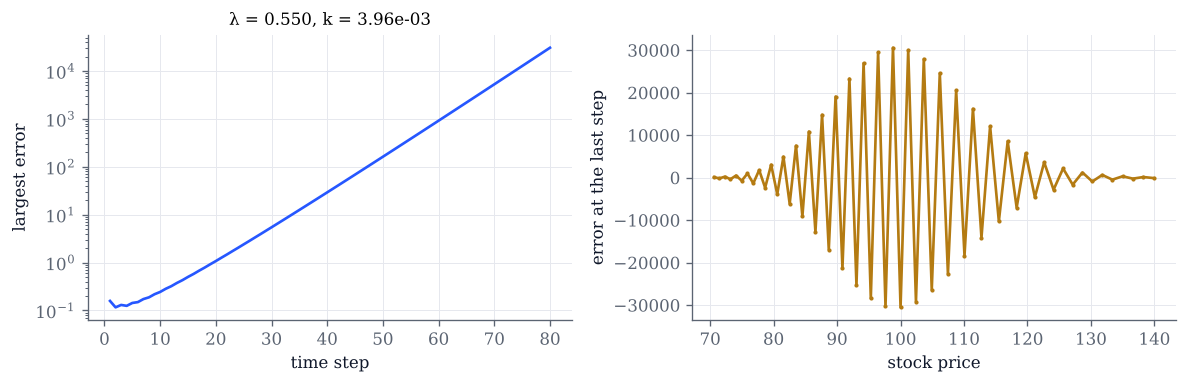

In [6]:
def stability(lam=0.55, steps=80, n_x=200, K=100.0, sigma=0.2):
    r, T = 0.05, 1.0
    a, b, c = bs_log_coefficients(r, sigma)
    y = log_grid(K, T, sigma, n_x)
    x = np.exp(y)
    h = y[1] - y[0]
    k = lam * h * h / a
    res = theta_scheme(np.maximum(x - K, 0.0), y, steps * k, steps, a, b, c, 0.0,
                       lambda tau: (0.0, x[-1] - K * np.exp(-r * tau)), keep=True)
    err = [np.max(np.abs(res["history"][m] - call(x, K, m * k, r, sigma))) for m in range(1, steps + 1)]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    ax.semilogy(np.arange(1, steps + 1), err, color=COBALT)
    ax.set(xlabel="time step", ylabel="largest error", title=f"λ = {lam:.3f}, k = {k:.2e}")
    m = (x > 0.7 * K) & (x < 1.4 * K)
    ax2.plot(x[m], res["u"][m] - call(x[m], K, steps * k, r, sigma), color=GOLD, marker=".", ms=3)
    ax2.set(xlabel="stock price", ylabel="error at the last step")
    fig.tight_layout()
    plt.show()

stability()

In [7]:
# Explore: find the threshold in λ. Does it depend on the number of nodes or on σ?
interact(stability,
         lam=FloatSlider(value=0.55, min=0.1, max=0.7, step=0.01, continuous_update=False, description="λ"),
         steps=IntSlider(value=80, min=10, max=300, step=10, continuous_update=False, description="steps"),
         n_x=IntSlider(value=200, min=50, max=600, step=50, continuous_update=False, description="nodes"),
         K=FloatSlider(value=100.0, min=80.0, max=120.0, step=5.0, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.5, step=0.05, continuous_update=False, description="σ"));

### On a grid in the price itself

The course's example: the explicit scheme on the grid $S_j=j\,\delta S$, $0\le j\le M$, $S_M=400$, with $N=10^4$ time
steps, for a call with $K=100$, $\sigma=20\%$, $r=5\%$, $T=1$ (Remark 16.12). The local ratio $\frac12\sigma^2j^2\delta t$ grows
with $j$, so the top of the grid sets the stability limit: refining the grid in $S$ at fixed $N$ makes the scheme
explode near $S_M$. The middle weights are nonnegative for $M\le500$, the spectral radius of the iteration matrix
exceeds $1$ from $M=510$ on.

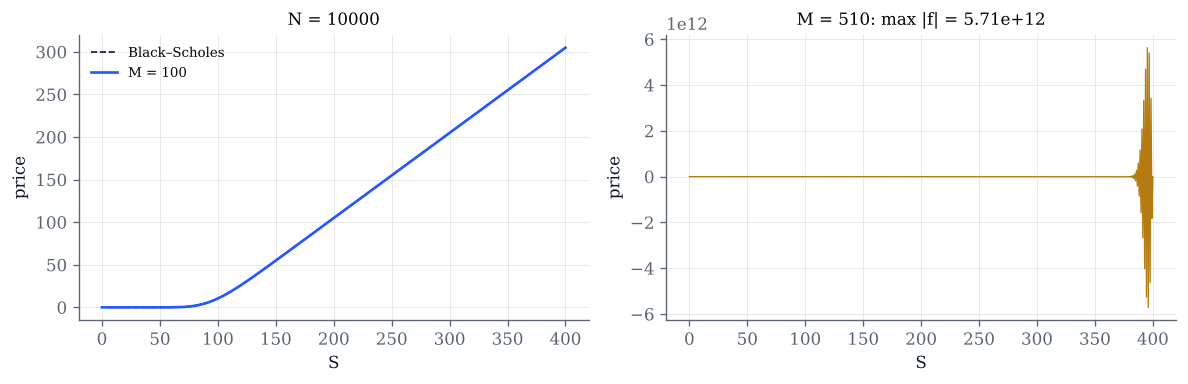

middle weights nonnegative: False   bound dt (sigma^2 (M-1)^2 + r) = 1.0363


In [8]:
def s_grid(M=510, N=10_000, discounted_boundary=True):
    K, r, sigma, T = 100.0, 0.05, 0.2, 1.0
    res = explicit_s_grid(K, r, sigma, T, 400.0, M, N, discounted_boundary)
    good = explicit_s_grid(K, r, sigma, T, 400.0, 100, N, discounted_boundary)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    S = good["S"][1:]
    ax.plot(S, call(S, K, T, r, sigma), color=INK, ls="--", lw=1, label="Black–Scholes")
    ax.plot(good["S"], good["f"], color=COBALT, label="M = 100")
    ax.set(xlabel="S", ylabel="price", title=f"N = {N}")
    ax.legend(fontsize=8)
    ax2.plot(res["S"], res["f"], color=GOLD, lw=0.8)
    ax2.set(xlabel="S", ylabel="price", title=f"M = {M}: max |f| = {res['max_abs']:.3g}")
    fig.tight_layout()
    plt.show()
    print("middle weights nonnegative:", res["positive"], "  bound dt (sigma^2 (M-1)^2 + r) =",
          round(T / N * (sigma**2 * (M - 1) ** 2 + r), 4))

s_grid()

In [9]:
# Explore: M = 505 is still fine although some middle weights are negative; M = 510 is not.
# With the undiscounted boundary value S_max - K, look at the error near S_max for M = 100.
interact(s_grid,
         M=IntSlider(value=510, min=100, max=520, step=1, continuous_update=False, description="M"),
         N=IntSlider(value=10_000, min=2_000, max=20_000, step=1_000, continuous_update=False, description="N"),
         discounted_boundary=True);

## 3. Convergence orders, and Crank–Nicolson near the strike

The error at $S_0=K$ of the four schemes on a call: the explicit scheme with $k=0.4h^2/a$, the others with $k=h/\sigma$
(Theorem 16.10). The kink of the payoff spoils Crank–Nicolson: its amplification factor tends to $-1$ for high
frequencies when $\lambda=ak/h^2$ is large, and the gamma oscillates near the strike. Rannacher's start, four implicit
half-steps, damps those frequencies and restores the second order.

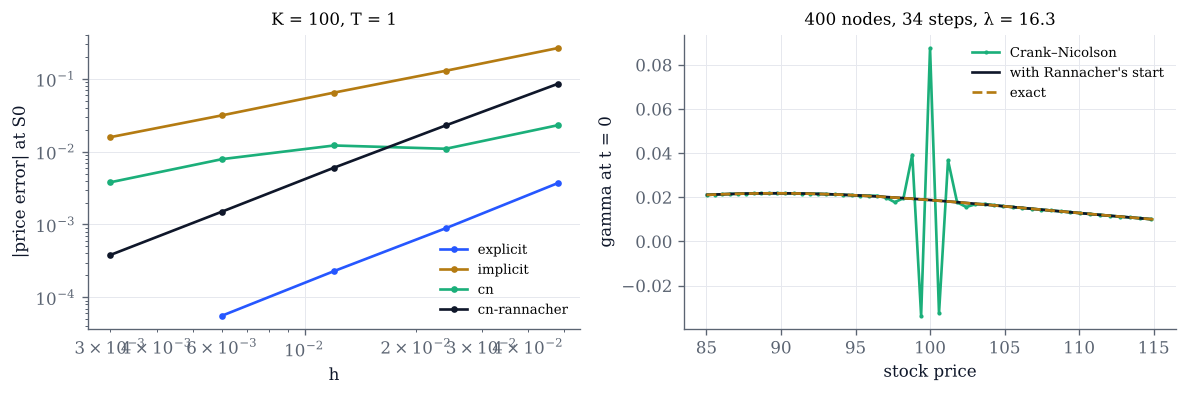

In [10]:
def convergence(K=100.0, T=1.0, sigma=0.2, ratio=1.0):
    S0, r = 100.0, 0.05
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    for scheme, col in (("explicit", COBALT), ("implicit", GOLD), ("cn", GREEN), ("cn-rannacher", INK)):
        lev = [50, 100, 200, 400] if scheme == "explicit" else [50, 100, 200, 400, 800]
        tab = convergence_table("call", S0, K, T, r, sigma, lev, scheme, ratio=ratio)
        ax.loglog(tab["h"], np.abs(tab["error"]) + 1e-16, marker="o", ms=3, color=col, label=scheme)
    ax.set(xlabel="h", ylabel="|price error| at S0", title=f"K = {K:g}, T = {T:g}")
    ax.legend(fontsize=8)
    n_x = 400
    h = 2 * 6 * sigma * np.sqrt(T) / n_x
    n_t = max(2, int(np.ceil(T * sigma / (ratio * h))))
    for ran, col, lab in ((0, GREEN, "Crank–Nicolson"), (2, INK, "with Rannacher's start")):
        res = european_fd("call", S0, K, T, r, sigma, n_x, n_t, theta=0.5, rannacher=ran)
        _, gam = grid_greeks(res["x"], res["v"])
        xs = res["x"][1:-1]
        m = (xs > 0.85 * K) & (xs < 1.15 * K)
        ax2.plot(xs[m], gam[m], color=col, marker="." if ran == 0 else None, ms=3, label=lab)
    xx = np.linspace(0.85 * K, 1.15 * K, 200)
    ax2.plot(xx, greeks(xx, K, T, r, sigma, "call")["gamma"], color=GOLD, ls="--", label="exact")
    ax2.set(xlabel="stock price", ylabel="gamma at t = 0", title=f"400 nodes, {n_t} steps, λ = {0.5*sigma**2*(T/n_t)/h**2:.1f}")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

convergence()

In [11]:
# Explore: ratio = k sigma / h. Small ratios mean small lambda: does Crank–Nicolson still oscillate?
interact(convergence,
         K=FloatSlider(value=100.0, min=80.0, max=120.0, step=1.0, continuous_update=False, description="K"),
         T=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="T"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.5, step=0.05, continuous_update=False, description="σ"),
         ratio=FloatLogSlider(value=1.0, base=10, min=-2, max=1, step=0.25, continuous_update=False, description="k σ / h"));

## 4. The American put and its exercise boundary

At every time step the projected scheme solves a complementarity problem: the value is at least the payoff, and
where it is strictly larger the discrete Black–Scholes equation holds (Proposition 16.13). Projected SOR solves it by
Gauss–Seidel sweeps clipped at the payoff. The exercise boundary is the largest price at which the value equals
the payoff; it starts above the perpetual level $L^*=2rK/(2r+\sigma^2)$ and rises to $K$ at maturity.

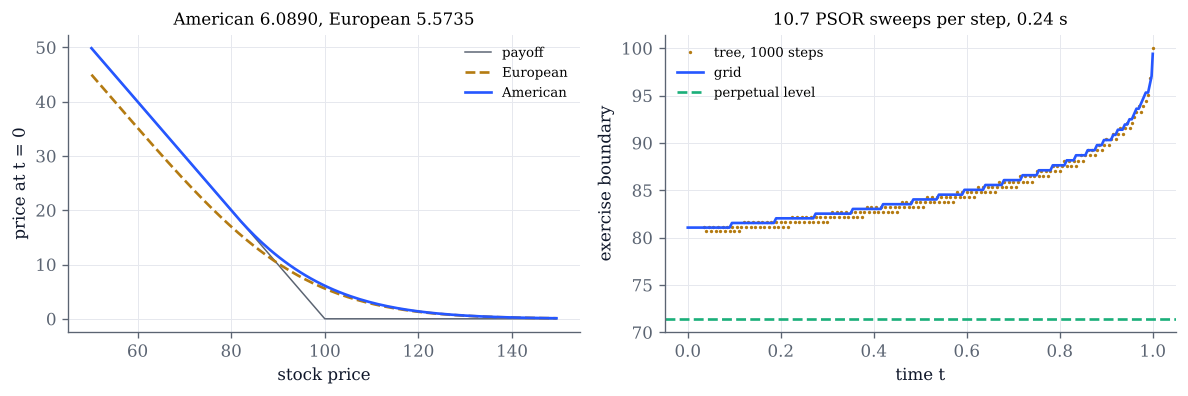

In [12]:
def american(r=0.05, sigma=0.2, T=1.0, n_x=400, omega=1.2):
    K, S0 = 100.0, 100.0
    t0 = time.perf_counter()
    res = american_put_fd(S0, K, T, r, sigma, n_x=n_x, n_t=n_x // 2, omega=omega, keep=True)
    elapsed = time.perf_counter() - t0
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    m = (res["x"] > 50) & (res["x"] < 150)
    xs = res["x"][m]
    ax.plot(xs, np.maximum(K - xs, 0), color=GREY, lw=0.9, label="payoff")
    ax.plot(xs, put(xs, K, T, r, sigma), color=GOLD, ls="--", label="European")
    ax.plot(xs, res["v"][m], color=COBALT, label="American")
    ax.set(xlabel="stock price", ylabel="price at t = 0", title=f"American {res['price']:.4f}, European {put(S0, K, T, r, sigma):.4f}")
    ax.legend(fontsize=8)
    N = 1000
    u, d, rn, _ = crr_parameters(T, N, r, sigma)
    ax2.plot(np.linspace(0, T, N + 1)[::5], early_exercise_boundary(K, S0, u, d, rn, N)[::5], ".", ms=2, color=GOLD, label="tree, 1000 steps")
    ax2.plot(res["t"], res["boundary"], color=COBALT, label="grid")
    if r > 0:
        ax2.axhline(2 * r * K / (2 * r + sigma**2), color=GREEN, ls="--", label="perpetual level")
    ax2.set(xlabel="time t", ylabel="exercise boundary", title=f"{res['mean_iterations']:.1f} PSOR sweeps per step, {elapsed:.2f} s")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

american()

In [13]:
# Explore: which omega minimizes the number of sweeps? What happens to the boundary when r -> 0?
interact(american,
         r=FloatSlider(value=0.05, min=0.0, max=0.15, step=0.01, continuous_update=False, description="r"),
         sigma=FloatSlider(value=0.2, min=0.1, max=0.6, step=0.05, continuous_update=False, description="σ"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         n_x=IntSlider(value=400, min=100, max=800, step=100, continuous_update=False, description="nodes"),
         omega=FloatSlider(value=1.2, min=0.2, max=1.9, step=0.1, continuous_update=False, description="ω"));

## 5. A physics-informed network, in NumPy

A network with one hidden layer, $u_w(\tau,y)=c_0+\sum_ic_i\tanh(w_iy+s_i\tau+b_i)$, is trained to make the residual
$\partial_\tau u-a\,\partial_{yy}u-b\,\partial_yu+cu$ small at random points, and to match the payoff at $\tau=0$ and the
boundary values (Remark 16.14). The derivatives of tanh are written by hand, and so are the gradients of the loss; the
optimizer is Adam. The call has strike $K=1$, with $r=5\%$ and $\sigma=20\%$, on $x\in[0.5,2]$, $\tau\in[0,1]$.
Compare the error with that of Crank–Nicolson with Rannacher's start on $200$ nodes, and the time each takes.

PINN: 4000 iterations in 3.3 s, final loss 7.98e-05
  tau = 0.05: PINN max error 1.6e-02; Crank-Nicolson + Rannacher, 200 nodes: 1.2e-04 in 0.5 ms
  tau = 0.50: PINN max error 2.4e-03; Crank-Nicolson + Rannacher, 200 nodes: 6.2e-05 in 1.1 ms
  tau = 1.00: PINN max error 1.7e-03; Crank-Nicolson + Rannacher, 200 nodes: 6.1e-05 in 1.4 ms


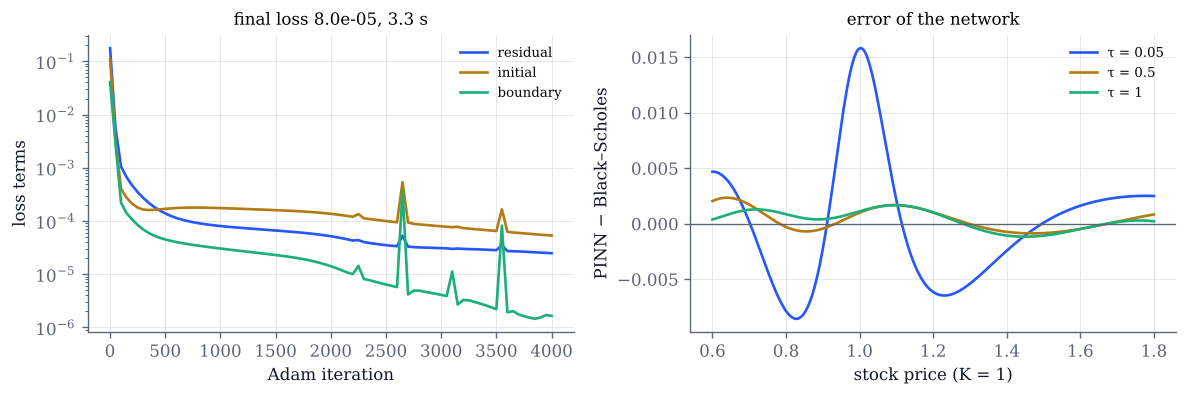

In [14]:
def pinn(n_hidden=24, n_iter=4000, lr=0.01, n_points=400, seed=0):
    r, sigma, T = 0.05, 0.2, 1.0
    a, b, c = bs_log_coefficients(r, sigma)
    lo, hi = np.log(0.5), np.log(2.0)
    rng = np.random.default_rng(seed)
    tb = np.linspace(0, T, 21)
    y0 = np.linspace(lo, hi, 101)
    pts = dict(tau_r=rng.uniform(0, T, n_points), y_r=rng.uniform(lo, hi, n_points), y_0=y0,
               g_0=np.maximum(np.exp(y0) - 1, 0), tau_b=np.r_[tb, tb],
               y_b=np.r_[np.full(21, lo), np.full(21, hi)], g_b=np.r_[np.zeros(21), np.exp(hi) - np.exp(-r * tb)])
    t0 = time.perf_counter()
    p, hist = pinn_train(pts, a, b, c, n_hidden=n_hidden, n_iter=n_iter, lr=lr, seed=seed)
    t_pinn = time.perf_counter() - t0
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.semilogy(hist[:, 0], hist[:, 2], color=COBALT, label="residual")
    ax.semilogy(hist[:, 0], hist[:, 3], color=GOLD, label="initial")
    ax.semilogy(hist[:, 0], hist[:, 4], color=GREEN, label="boundary")
    ax.set(xlabel="Adam iteration", ylabel="loss terms", title=f"final loss {hist[-1, 1]:.1e}, {t_pinn:.1f} s")
    ax.legend(fontsize=8)
    yy = np.linspace(np.log(0.6), np.log(1.8), 400)
    print(f"PINN: {n_iter} iterations in {t_pinn:.1f} s, final loss {hist[-1, 1]:.2e}")
    for tau, col in ((0.05, COBALT), (0.5, GOLD), (1.0, GREEN)):
        err = pinn_eval(p, np.full(yy.size, tau), yy)["u"] - call(np.exp(yy), 1.0, tau, r, sigma)
        ax2.plot(np.exp(yy), err, color=col, label=f"τ = {tau:g}")
        t0 = time.perf_counter()
        fd = european_fd("call", 1.0, 1.0, tau, r, sigma, 200, max(4, int(np.ceil(100 * np.sqrt(tau) / 6))), rannacher=2)
        t_fd = time.perf_counter() - t0
        mm = (fd["x"] > 0.6) & (fd["x"] < 1.8)
        e_fd = np.max(np.abs(fd["v"][mm] - call(fd["x"][mm], 1.0, tau, r, sigma)))
        print(f"  tau = {tau:4.2f}: PINN max error {np.max(np.abs(err)):.1e};"
              f" Crank-Nicolson + Rannacher, 200 nodes: {e_fd:.1e} in {1000 * t_fd:.1f} ms")
    ax2.axhline(0, color=GREY, lw=0.8)
    ax2.set(xlabel="stock price (K = 1)", ylabel="PINN − Black–Scholes", title="error of the network")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

pinn()

In [15]:
# Explore: more units, more iterations, other seeds. Where is the error largest, and does it go away?
interact(pinn,
         n_hidden=IntSlider(value=24, min=4, max=64, step=4, continuous_update=False, description="units"),
         n_iter=IntSlider(value=4000, min=500, max=12000, step=500, continuous_update=False, description="iterations"),
         lr=FloatLogSlider(value=0.01, base=10, min=-3.5, max=-1, step=0.25, continuous_update=False, description="rate"),
         n_points=IntSlider(value=400, min=100, max=2000, step=100, continuous_update=False, description="points"),
         seed=IntSlider(value=0, min=0, max=20, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\sigma=0.6$, $T=3$ and $M=50$: the discounted payoff is now very skewed. How does the coverage
  compare with $95\%$, and which side of the price do the failing intervals fall on?
- In section 1 (cost and accuracy), read off the slope of the "best $n$" curve. How much must the budget grow to halve the
  error, with and without the bias?
- In section 2, the threshold is $\lambda=\frac12$ whatever the number of nodes. Why is it not exactly visible after a few steps
  for $\lambda$ just above $\frac12$, and what decides how fast the error grows?
- In section 2, on the grid in the price, find the largest $M$ that is stable for $N=5000$ steps. Does it scale like
  $\sqrt N$, as the bound $\delta t\,\sigma^2M^2\le1$ suggests?
- In section 3, take a short maturity, $T=0.1$. Why do the oscillations of the Crank–Nicolson gamma get worse?
- In section 4, set $r=0$. What happens to the exercise boundary, and why?
- In section 5, train for longer or with more units. The loss keeps falling: does the error near the strike at
  $\tau=0.05$ fall as fast?